# CloudGuard-Water: Phase 3 — Baseline Model Training & Evaluation

**Course**: Machine Learning for Cloud Services  
**Project**: CloudGuard-Water: Intelligent and Explainable Water Quality Classification  
**Dataset**: `data/water_quality_dataset1.csv` (100,800 rows × 5 columns)  

---

### Objectives:
1. Formulate the feature matrix $X$ and target vector $y$.
2. Encode classes: `0 = Safe`, `1 = Unsafe` (Positive alarm class).
3. Execute a stratified 80/20 train-test split (`test_size=0.20`, `random_state=42`, `stratify=y`).
4. Train three baseline models:
   - **Logistic Regression** (with `StandardScaler` inside a Pipeline)
   - **Decision Tree** (unscaled, `max_depth=5` for interpretability)
   - **Random Forest** (unscaled ensemble, `n_estimators=100`, `max_depth=8`)
5. Evaluate all models on Accuracy, Precision, Recall, F1, Macro F1, Weighted F1, and Confusion Matrices.
6. Analyze the operational consequences of False Negatives (predicting `Safe` when water is actually `Unsafe`).
7. Visualize the Decision Tree decision rules and plot Random Forest feature importances.
8. Persist trained models using `joblib` into `models/`.


In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid", palette="muted")


## 1. Data Loading & Target Encoding
We load the dataset and encode the target:
- **`Safe` → `0`** (Negative class: Potable water conforming to standards)
- **`Unsafe` → `1`** (Positive class: Contaminated water exceeding safety thresholds)


In [2]:
def find_dataset():
    candidates = [
        Path("data/water_quality_dataset1.csv"),
        Path("../data/water_quality_dataset1.csv"),
        Path("../../data/water_quality_dataset1.csv"),
        Path("data/water_quality_dataset1_original.csv"),
        Path("../data/water_quality_dataset1_original.csv"),
        Path("Cloudguard/data/water_quality_dataset1.csv"),
        Path("/content/Cloudguard/data/water_quality_dataset1.csv"),
        Path("/content/data/water_quality_dataset1.csv"),
    ]
    for p in candidates:
        if p.exists():
            return p
    curr = Path.cwd().resolve()
    for parent in [curr] + list(curr.parents):
        for name in ["water_quality_dataset1.csv", "water_quality_dataset1_original.csv"]:
            target = parent / "data" / name
            if target.exists():
                return target
    raise FileNotFoundError("Could not find dataset in standard locations.")

data_file = find_dataset()
df = pd.read_csv(data_file)
print(f"Loaded dataset: {df.shape[0]:,} rows × {df.shape[1]} columns")

feature_cols = ['pH', 'TDS_ppm', 'Turbidity_NTU', 'Temperature_C']
X = df[feature_cols].copy()

target_mapping = {'Safe': 0, 'Unsafe': 1}
y = df['Label'].map(target_mapping)

print("\nTarget Encoding:")
print(f"  'Safe'   -> 0 (Count: {list(y).count(0):,}, {list(y).count(0)/len(y)*100:.2f}%)")
print(f"  'Unsafe' -> 1 (Count: {list(y).count(1):,}, {list(y).count(1)/len(y)*100:.2f}%)")


Loaded dataset: 100,800 rows × 5 columns

Target Encoding:
  'Safe'   -> 0 (Count: 30,240, 30.00%)
  'Unsafe' -> 1 (Count: 70,560, 70.00%)


## 2. Stratified 80/20 Train-Test Split
Preserving the exact 70:30 class distribution across both training (80,640 samples) and testing (20,160 samples) subsets.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

safe_train = list(y_train).count(0)
unsafe_train = list(y_train).count(1)
safe_test = list(y_test).count(0)
unsafe_test = list(y_test).count(1)
print(f"Training set : {len(X_train):,} samples (80.00%)")
print(f"  Safe (0)   : {safe_train:,} ({safe_train/len(y_train)*100:.2f}%)")
print(f"  Unsafe (1) : {unsafe_train:,} ({unsafe_train/len(y_train)*100:.2f}%)")
print(f"Testing set  : {len(X_test):,} samples (20.00%)")
print(f"  Safe (0)   : {safe_test:,} ({safe_test/len(y_test)*100:.2f}%)")
print(f"  Unsafe (1) : {unsafe_test:,} ({unsafe_test/len(y_test)*100:.2f}%)")


Training set : 80,640 samples (80.00%)
  Safe (0)   : 24,192 (30.00%)
  Unsafe (1) : 56,448 (70.00%)
Testing set  : 20,160 samples (20.00%)
  Safe (0)   : 6,048 (30.00%)
  Unsafe (1) : 14,112 (70.00%)


## 3. Model Training
We initialize and train three baseline models:
1. **Logistic Regression**: Scaled via `StandardScaler` inside a Pipeline.
2. **Decision Tree**: Unscaled, `max_depth=5` for interpretability.
3. **Random Forest**: Unscaled ensemble with 100 trees, `max_depth=8`.


In [4]:
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(random_state=42, max_iter=1000))
    ]),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, criterion='gini', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=8, criterion='gini', random_state=42, n_jobs=-1)
}

trained_models = {}
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model

print("All models successfully trained!")


Training Logistic Regression...
Training Decision Tree...


Training Random Forest...


All models successfully trained!


## 4. Model Evaluation & Comparison
Evaluating all models on the unseen 20,160-sample test set.


In [5]:
comparison_records = []
confusion_matrices = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    
    prec_safe = precision_score(y_test, y_pred, pos_label=0)
    rec_safe = recall_score(y_test, y_pred, pos_label=0)
    f1_safe = f1_score(y_test, y_pred, pos_label=0)
    
    prec_unsafe = precision_score(y_test, y_pred, pos_label=1)
    rec_unsafe = recall_score(y_test, y_pred, pos_label=1)
    f1_unsafe = f1_score(y_test, y_pred, pos_label=1)
    
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    weighted_f1 = f1_score(y_test, y_pred, average='weighted')
    
    cm = confusion_matrix(list(y_test), [int(p) for p in y_pred])
    confusion_matrices[name] = cm
    tn, fp, fn, tp = cm.ravel()
    
    comparison_records.append({
        'Model': name,
        'Accuracy': acc,
        'Precision (Safe)': prec_safe,
        'Recall (Safe)': rec_safe,
        'F1 (Safe)': f1_safe,
        'Precision (Unsafe)': prec_unsafe,
        'Recall (Unsafe)': rec_unsafe,
        'F1 (Unsafe)': f1_unsafe,
        'Macro F1': macro_f1,
        'Weighted F1': weighted_f1,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp
    })

comparison_df = pd.DataFrame(comparison_records)
comparison_df.round(6)


,Model,Accuracy,Precision (Safe),Recall (Safe),F1 (Safe),Precision (Unsafe),Recall (Unsafe),F1 (Unsafe),Macro F1,Weighted F1,TN,FP,FN,TP
0,Logistic Regression,0.999901,0.999669,1.000000,0.999835,1.000000,0.999858,0.999929,0.999882,0.999901,6048,0,2,14110
1,Decision Tree,0.999901,0.999835,0.999835,0.999835,0.999929,0.999929,0.999929,0.999882,0.999901,6047,1,1,14111
2,Random Forest,0.999901,0.999835,0.999835,0.999835,0.999929,0.999929,0.999929,0.999882,0.999901,6047,1,1,14111


## 5. Confusion Matrices & Operational Error Analysis

In IoT water safety monitoring:
- **False Positive (FP)**: Safe water predicted as Unsafe $\rightarrow$ triggers an unnecessary inspection or filter backwash (minor operational cost).
- **False Negative (FN)**: Contaminated water predicted as Safe $\rightarrow$ dangerous failure mode where contaminated water passes into public drinking supplies without automated valve shutoff.


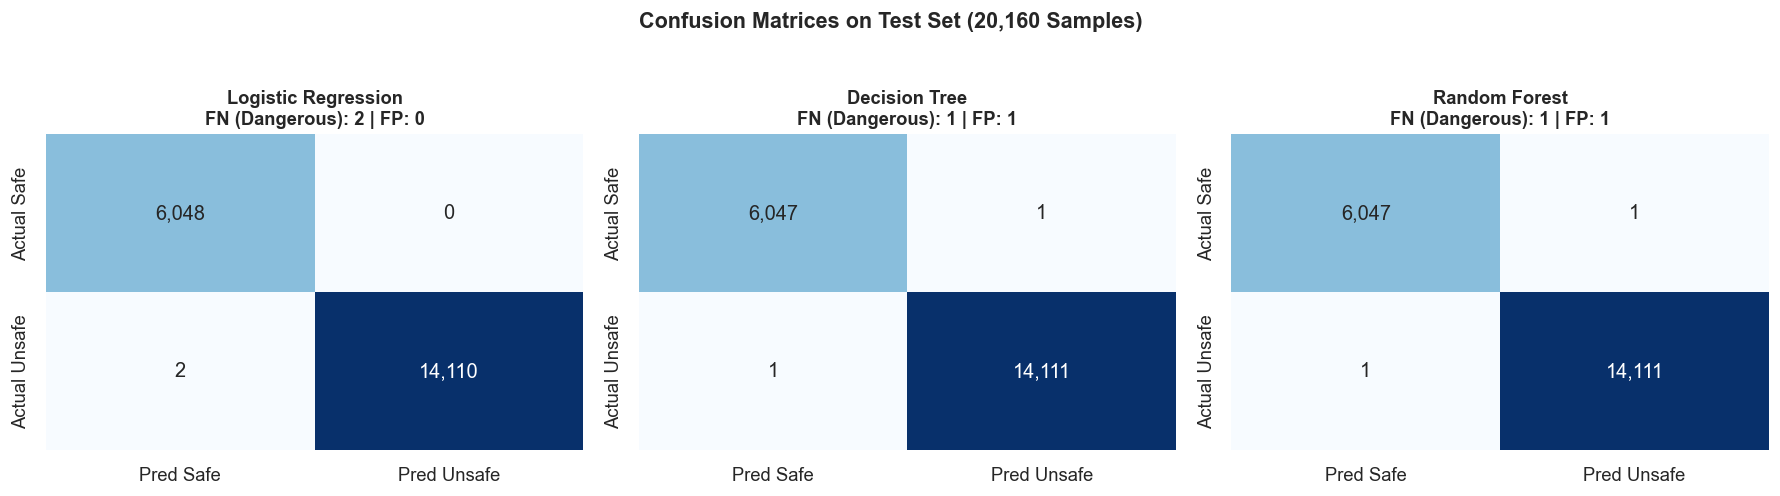

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for idx, (name, cm) in enumerate(confusion_matrices.items()):
    ax = axes[idx]
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred Safe', 'Pred Unsafe'],
                yticklabels=['Actual Safe', 'Actual Unsafe'])
    ax.set_title(f"{name}\nFN (Dangerous): {cm[1, 0]} | FP: {cm[0, 1]}", fontsize=11, fontweight='bold')

plt.suptitle("Confusion Matrices on Test Set (20,160 Samples)", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 6. Model Explainability — Decision Tree Visualization
Visualizing the exact if-then decision boundaries for regulatory transparency.


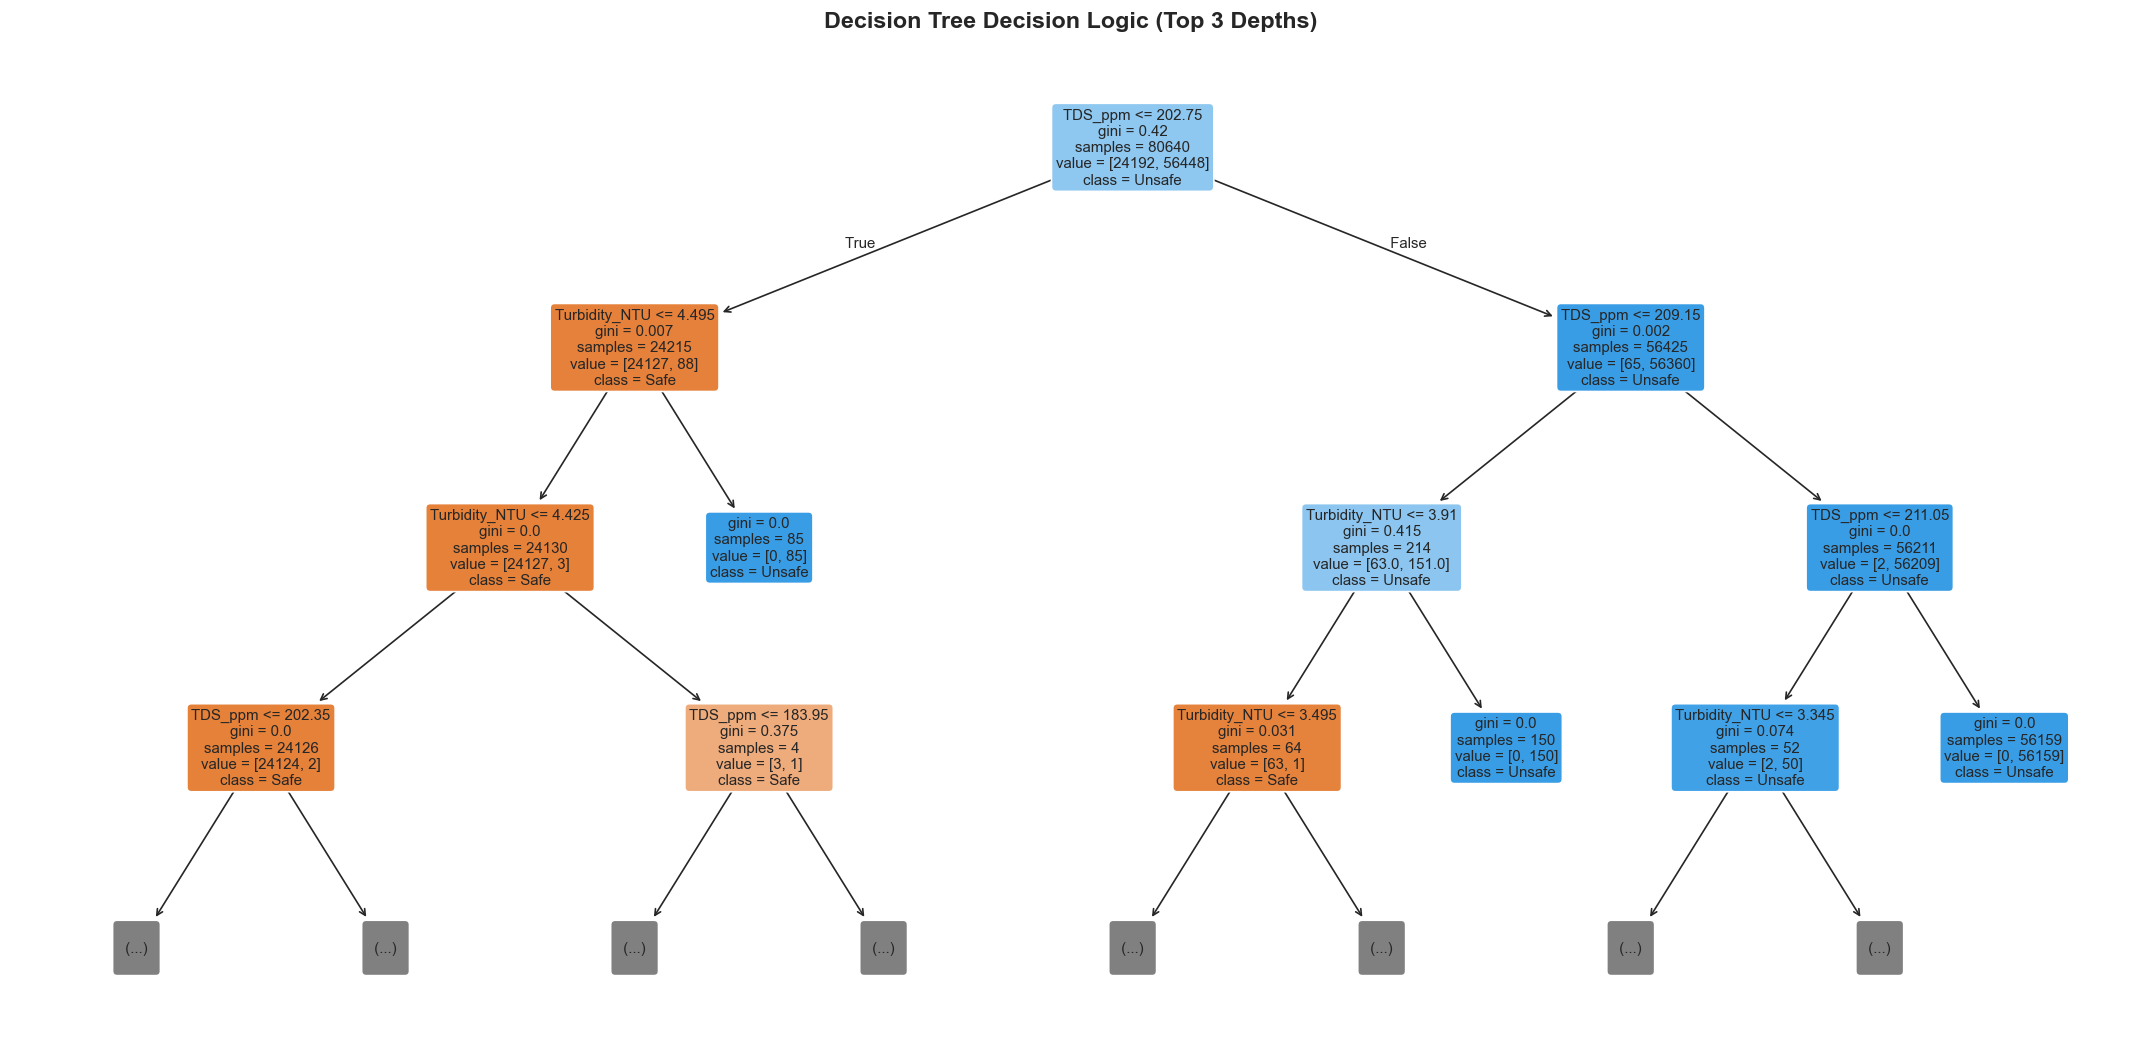

In [7]:
fig, ax = plt.subplots(figsize=(18, 9))
plot_tree(
    trained_models['Decision Tree'],
    feature_names=feature_cols,
    class_names=['Safe', 'Unsafe'],
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3,
    ax=ax
)
ax.set_title("Decision Tree Decision Logic (Top 3 Depths)", fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 7. Model Explainability — Random Forest Feature Importance
Calculating Mean Decrease in Impurity (Gini Importance) across all 100 ensemble trees.


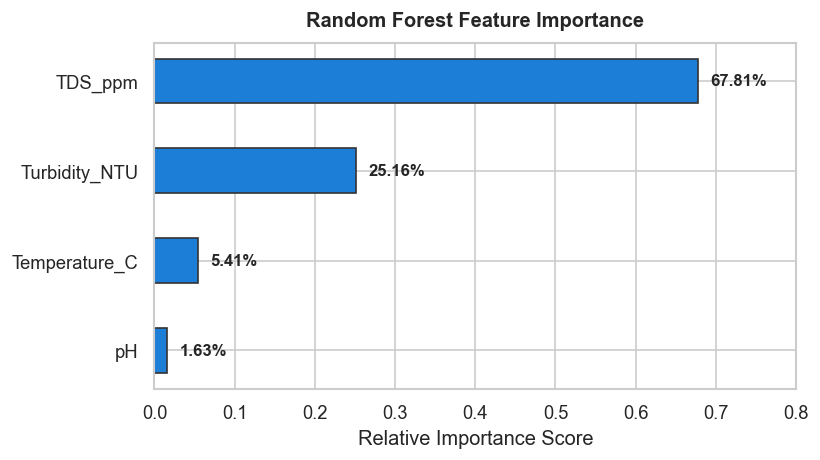

Feature Importance Ranking:
  TDS_ppm           : 0.6781 (67.81%)
  Turbidity_NTU     : 0.2516 (25.16%)
  Temperature_C     : 0.0541 (5.41%)
  pH                : 0.0163 (1.63%)


In [8]:
rf = trained_models['Random Forest']
importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(list(importances.index), list(importances.values), color="#1c7ed6", edgecolor="#333", height=0.5)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.015, bar.get_y() + bar.get_height()/2., f"{w*100:.2f}%", va='center', fontweight='bold', fontsize=10)

ax.set_title("Random Forest Feature Importance", fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel("Relative Importance Score")
ax.set_xlim(0, max(importances.values) * 1.18)
plt.tight_layout()
plt.show()

print("Feature Importance Ranking:")
for feat, imp in importances.iloc[::-1].items():
    print(f"  {feat:<18}: {imp:.4f} ({imp*100:.2f}%)")


## 8. Persisting Models to `models/`
Saving all trained models via `joblib` for downstream deployment into the cloud inference microservice.


In [9]:
models_dir = Path("../models")
if not models_dir.exists():
    models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)

for name, model in trained_models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"
    save_path = models_dir / filename
    joblib.dump(model, save_path)
    print(f"Saved: {save_path.resolve()}")

print("\nAll models successfully serialized!")


Saved: D:\E0224033\ML_for_Cl_Ser\CL\LB_Proj\models\logistic_regression.joblib
Saved: D:\E0224033\ML_for_Cl_Ser\CL\LB_Proj\models\decision_tree.joblib
Saved: D:\E0224033\ML_for_Cl_Ser\CL\LB_Proj\models\random_forest.joblib

All models successfully serialized!
